Spectrum of Sodium-22

In [169]:
import matplotlib.pyplot as plt
import numpy as np
 
from lmfit import models
from lmfit.models import GaussianModel

In [170]:
with open("spectrum_na22.csv", "r") as file:
    full_pulseheight = []
    full_counts = []
    i = 0

    for line in file:
        data = line.split(',')

        if i > 0:
            full_pulseheight.append(float(data[0]))
            full_counts.append(float(data[1]))
                # pulseheight.append(float(data[0]))
                # counts.append(float(data[1]))
            # if float(data[0]) > 1750:
                # pulseheight.append(float(data[0]))
                # counts.append(float(data[1]))
        else:
            i+=1


In [171]:
pulseheight = []
counts = []
for i in range(0, len(full_pulseheight)):
    if full_pulseheight[i] > 1750: #and full_pulseheight[i] <2400:
        pulseheight.append(full_pulseheight[i])
        counts.append(full_counts[i])

# pulseheight.append(float(data[0]))
# counts.append(float(data[1]))

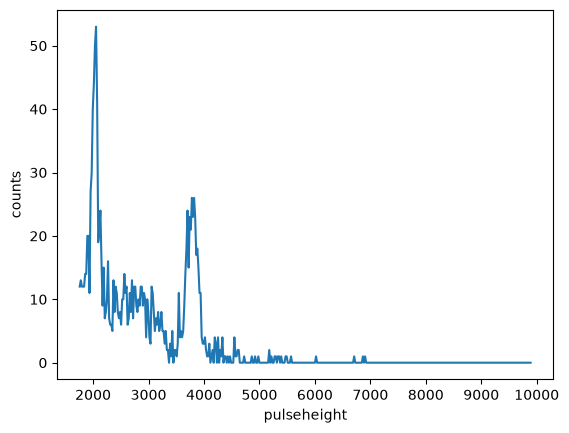

In [172]:
plt.plot(pulseheight, counts)
plt.xlabel("pulseheight")
plt.ylabel("counts")
plt.show()

In [ ]:
# def gauss(x, a, b, c):
#     y = a * np.exp(- ((x-b)**2) / (2*(c)**2))
#     return y

# gauss = GaussianModel()

def gaussian(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2))

def multiple_gaussians(x, A1, mu1, sigma1, A2, mu2, sigma2, A3, mu3, sigma3):
    return gaussian(x, A1, mu1, sigma1) + gaussian(x, A2, mu2, sigma2) + gaussian(x,A3,mu3,sigma3)

In [ ]:
spectrum = models.Model(multiple_gaussians)
fit_result = spectrum.fit(counts, x=pulseheight, A1=38, mu1=2000, sigma1=51, A2=10, mu2=2100, sigma2=1400, A3=25, mu3=3800, sigma3=500)

print(fit_result.fit_report())

[[Model]]
    Model(two_gaussians)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 102
    # data points      = 415
    # variables        = 9
    chi-square         = 1234.26665
    reduced chi-square = 3.04006565
    Akaike info crit   = 470.330806
    Bayesian info crit = 506.585313
    R-squared          = 0.94419310
[[Variables]]
    A1:      38.0964746 +/- 1.06241423 (2.79%) (init = 38)
    mu1:     2032.64746 +/- 1.50119038 (0.07%) (init = 2000)
    sigma1:  47.7631520 +/- 1.63358762 (3.42%) (init = 51)
    A2:      12.8223737 +/- 0.75914289 (5.92%) (init = 10)
    mu2:     1673.20907 +/- 183.018479 (10.94%) (init = 2100)
    sigma2:  1184.72059 +/- 110.398842 (9.32%) (init = 1400)
    A3:      22.4752761 +/- 0.75704543 (3.37%) (init = 25)
    mu3:     3790.25336 +/- 3.55721541 (0.09%) (init = 3800)
    sigma3:  94.5502227 +/- 3.87538730 (4.10%) (init = 500)
[[Correlations]] (unreported correlations are < 0.100)
    C(mu2, sigma2)    = -0.9311
    C(

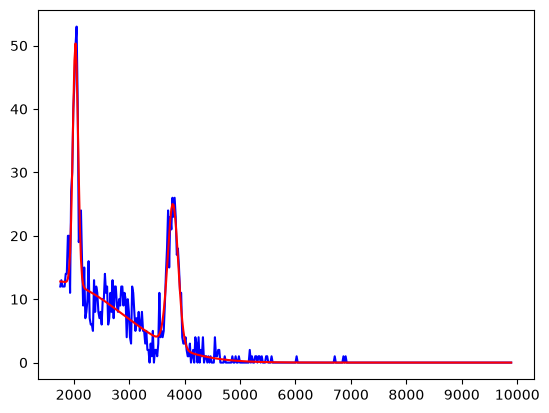

In [175]:
plt.plot(pulseheight, counts, 'b-')
plt.plot(pulseheight, fit_result.best_fit, 'r-')

plt.show()

In [178]:
pulseheight1 = fit_result.params['mu1'].value
# pulseheight2 = fit_result.params['mu2'].value
pulseheight3 = fit_result.params['mu3'].value

print(pulseheight1, pulseheight3)

2032.647463098942 3790.2533565841904
